# Fraud Prevention Case — Exploration, Predictive Modeling and Classification (January/2026)

## 1. Business Context and Objective
The Fraud Prevention team of the financial institution faces a dual challenge caused by fast-growing transaction volume. The two errors a fraud model can make pull in opposite directions:

| Error | What happens | Business cost |
|---|---|---|
| **False Negatives** | Frauds are not detected in time, because manual review does not scale | Direct financial loss |
| **False Positives** | Legitimate customers are wrongly blocked | Lower conversion and customer loyalty |

### What this notebook documents, end to end

| # | Topic | What is done |
|---|---|---|
| 1 | **Exploratory Data Analysis (EDA)** | 2025 history (`transacoes_historico_2025.csv`, $N = 523{,}525$ transactions) and an integrity check of the January/2026 file (`transacoes_jan2026.csv`, $N = 44{,}451$ transactions) |
| 2 | **Fraud regimes and features** | Discovery of the 4 spatio-temporal fraud regimes; feature engineering whose constants are fitted on training data only (see *Data Protocol*) |
| 3 | **Validation and model benchmark** | Month-by-month rolling-origin (walk-forward) validation, Jul–Dec/2025, run via `colab-cli` on a High-RAM Google Colab VM. 8 models: Logistic Regression, Random Forest, HistGB, XGBoost, LightGBM, CatBoost, Ensemble and a naive baseline. The `.joblib` artifacts are refit on all of 2025 after selection |
| 4 | **Seasonality** | December, Christmas proximity, holidays and vacation season, tested with an ablation against a model without calendar features |
| 5 | **Thresholds and financial impact** | Automatic blocking (`threshold = 0.50`) versus a step-up authentication queue (`F1-optimal threshold = 0.288`, chosen using prior months only) |
| 6 | **January/2026 classification and architecture** | Scoring of the January file and integration with the event-driven architecture (**Spring Boot + Apache Kafka + FastAPI + React Dashboard**) |

## How to Read This Notebook (no execution needed)

> **This notebook is published as a read-only report.** Every table, chart and number below was produced by a real run and is **saved in the file**, so you can read it top to bottom without running anything.

**The code cells only run where those files exist.** They load files produced by the training run (the raw transaction CSVs, the trained `.joblib` pipelines, the metrics JSON and the other training artifacts), which are *not* included in the published copy of this notebook. Without them the cells stop with a `FileNotFoundError`. The code is kept on purpose, to show exactly how each result was computed. Files referenced but not included:

| Referenced in the notebook | What it is |
|---|---|
| `data/transacoes_historico_2025.csv`, `data/transacoes_jan2026.csv` | Raw 2025 history (labeled) and January/2026 transactions (unlabeled) |
| `models/*_fraud_model_cv.joblib`, `models/fraud_models_cv.metrics.json`, `models/domain_params.json` | The 8 trained pipelines, the metrics report written by the training run, and the training-fitted constants |
| `deliverables/` (scored January file, ablation results, `figures/*.png`) | Outputs of the scoring run, the ablation experiment and the saved chart images |
| `scripts/` (e.g. `colab_train_and_score.sh`, `build_notebook.py`), `services/ml-inference-service/train.py` | Training runner, training script (executed remotely on Google Colab) and the script that builds this notebook |

**Where to find what**

| Section (markdown title) | Question it answers |
|---|---|
| Business Context and Objective | What problem is being solved and what is delivered |
| Schema, Data Quality and Class Balance | What the data looks like and why accuracy is the wrong metric |
| 4 Spatio-Temporal Regimes | *Where, when and how* fraud happens |
| Data Protocol | How training, selection and testing were separated to avoid optimistic numbers |
| How the Training Was Executed | Colab, `colab-cli`, CUDA, and what the GPU does and does not help |
| Model Comparison and Statistical Significance | Which of the 8 models to ship, and whether the differences are real |
| Seasonality | What December does to the model, and what could not be proven with one year |
| Ablation | Why the headline metric dropped versus the first version of the study |
| Dual-Threshold Strategy | The approve / step-up / block decision policy and its trade-offs |
| Choosing the Production Model | Why LightGBM, and which alternative is ready if priorities change |
| January/2026 classification (code cell output) | Risk-tier distribution and the 10 highest-risk transactions |
| Executive Conclusion | Results on January/2026 and the production architecture |
| How to Reproduce Everything | The commands that rebuild every artifact (see the note below) |

**A note on wording.** In several places the text compares the current work with the *legacy* (or *previous*) protocol. That is the first version of this study: a random 80/20 split with the decision threshold and the champion model chosen on the test set. It was replaced by the walk-forward protocol described in *Data Protocol*, and the *Ablation* section quantifies the difference.

**Reproduction note.** The commands in *How to Reproduce Everything* work in the full solution repository linked in the last section, not in a copy that contains only this notebook and the presentation.


## Data Dictionary and Metrics Glossary

**Data.** Column names are kept in Portuguese, exactly as in the source files. Customer identifiers are pseudonymised (`Cliente_<number>`) and merchant names are generic labels (e.g. *Gas Station*, *Restaurant X*). The only row-level data shown in the outputs is a table with the 10 highest-risk January/2026 transactions. Only the 2025 file carries the label; January/2026 is scored by the model.

| Column | Meaning |
|---|---|
| `datahora_transacao` | Timestamp of the transaction (source of hour, day, month and the calendar features) |
| `nome_estabelecimento`, `tipo_estabelecimento` | Merchant name and merchant category (E-commerce, Supermarket, Food & Beverage, Retail, Pharmacy, Fuel) |
| `valor_transacao` | Transaction amount in R\$ |
| `nome_cliente` | Pseudonymised customer identifier |
| `cidade`, `cidade_regiao`, `codigo_postal` | City, Brazilian macro-region (Sudeste, Sul, Nordeste) and postal code |
| `device_type`, `is_new_device` | Device used (mobile, desktop, tablet) and whether it is the customer's first time on that device |
| `turno` | Period of day (madrugada, manhã, tarde, noite) |
| `valor_categoria` | Amount band (baixo, medio, alto) |
| `score_interno` | The institution's current internal score, shown in the EDA to have no discriminative power |
| `temperatura_celsius` | Temperature at the transaction; behaves as noise in the EDA |
| `flag_fraude` | **Target.** Whether the transaction was fraud. Available for 2025 only |

**Metrics and terms**

| Term | Plain-language meaning |
|---|---|
| **Precision** | Of the transactions the model flags, the share that really are fraud |
| **Recall** | Of all real frauds, the share the model catches |
| **FPR** (False Positive Rate) | Share of *legitimate* customers wrongly flagged |
| **F1** | Single score balancing Precision and Recall |
| **PR-AUC** (Average Precision) | Quality of the ranking across all thresholds. The main metric here because fraud is only $\approx 4\%$ of the data; a random model scores $\approx$ the fraud rate |
| **ROC-AUC** | Probability that a random fraud is scored above a random legitimate transaction |
| **Brier score** | Mean squared error of the predicted probabilities (lower is better; measures calibration) |
| **Calibration** | Whether "30% probability" really means about 30% of such cases are fraud |
| **Threshold** | Probability cut-off that turns a score into an action. $0.50$ is the default; $0.288$ is the F1-optimal value chosen from past months |
| **Walk-forward / out-of-time** | Train on the past, test on the following month, so the model never sees the future |
| **Step-Up authentication** | Asking the customer for an extra confirmation (2FA, biometrics) instead of blocking |
| **Regime** | One of the 4 spatio-temporal patterns (merchant type, hour, region) that contain all the observed fraud |


In [1]:
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

BASE_DIR = Path.cwd()
METRICS_PATH = BASE_DIR / "models" / "fraud_models_cv.metrics.json"
HIST_CSV = BASE_DIR / "data" / "transacoes_historico_2025.csv"
JAN_CSV = BASE_DIR / "data" / "transacoes_jan2026.csv"
SCORED_JAN_CSV = BASE_DIR / "deliverables" / "transacoes_jan2026_classificadas.csv"

report = json.loads(METRICS_PATH.read_text(encoding="utf-8"))

# Read a sample and the schema metadata for a quick inspection
df_hist_sample = pd.read_csv(HIST_CSV, nrows=1000)
df_jan_sample = pd.read_csv(JAN_CSV, nrows=1000)

summary_schema = pd.DataFrame({
    "Column": report["raw_input_columns"] + ["flag_fraude (Target)"],
    "Type (2025)": [str(df_hist_sample[c].dtype) for c in report["raw_input_columns"]] + [str(df_hist_sample["flag_fraude"].dtype)],
    "Present in Jan/2026": [c in df_jan_sample.columns for c in report["raw_input_columns"]] + [False],
})
print(f"Total transactions in 2025: {report['dataset_rows']:,}")
print(f"Target distribution (2025): Legitimate (0) = {report['class_counts']['0']:,} | Fraud (1) = {report['class_counts']['1']:,} ({report['class_counts']['1']/report['dataset_rows']*100:.2f}%)")
print(f"Total transactions in January/2026 to classify: {report['january_2026_forecast']['total_transactions']:,}")
display(summary_schema)

Total transactions in 2025: 523,525
Target distribution (2025): Legitimate (0) = 503,040 | Fraud (1) = 20,485 (3.91%)
Total transactions in January/2026 to classify: 44,451


,Column,Type (2025),Present in Jan/2026
0,datahora_transacao,str,True
1,nome_estabelecimento,str,True
2,tipo_estabelecimento,str,True
3,valor_transacao,float64,True
4,nome_cliente,str,True
5,cidade,str,True
6,device_type,str,True
7,is_new_device,bool,True
8,temperatura_celsius,float64,True
9,codigo_postal,str,True


### Schema, Data Quality and Class Balance

**1. Data quality: both files are clean**

| File | Rows | Columns | Missing values | Typing |
|---|---|---|---|---|
| 2025 history | $523{,}525$ | 15 | **0%** | 100% consistent |
| January 2026 | $44{,}451$ | 14 | **0%** | 100% consistent |

**2. Class balance (2025): severe imbalance**

| Class | Transactions | Share |
|---|---|---|
| Legitimate (0) | $503{,}040$ | $96.09\%$ |
| Fraud (1) | $20{,}485$ | $3.91\%$ |

**Why this matters**
- The imbalance is about 1 fraud for every 25 legitimate transactions.
- Plain accuracy is misleading. A naive classifier that always predicts "not fraud" would reach $96.09\%$ accuracy with $0\%$ detection.
- So the primary metrics are **PR-AUC (Average Precision)**, **ROC-AUC**, **F1-score**, **Precision** and **Recall**.

,Regime,Time window,Geographic scope,Transactions (2025),Frauds (2025),Fraud rate (%)
0,"R1: Fuel stations, early morning",00h-08h,São Paulo and Rio de Janeiro,5495,2633,47.92
1,R2: Food & Beverage at lunch,12h-14h,South and Southeast regions (5 capitals),9274,4449,47.97
2,R3: E-commerce in the December seasonal peak,20h-21h (Dec),Nationwide (all 7 capitals),779,446,57.25
3,"R4: Critical late-night window, all merchant t...",22h-23h,Nationwide (all sectors and cities),43614,12957,29.71
4,Outside the 4 critical regimes (safe zone),All other hours,Nationwide,464363,0,0.00


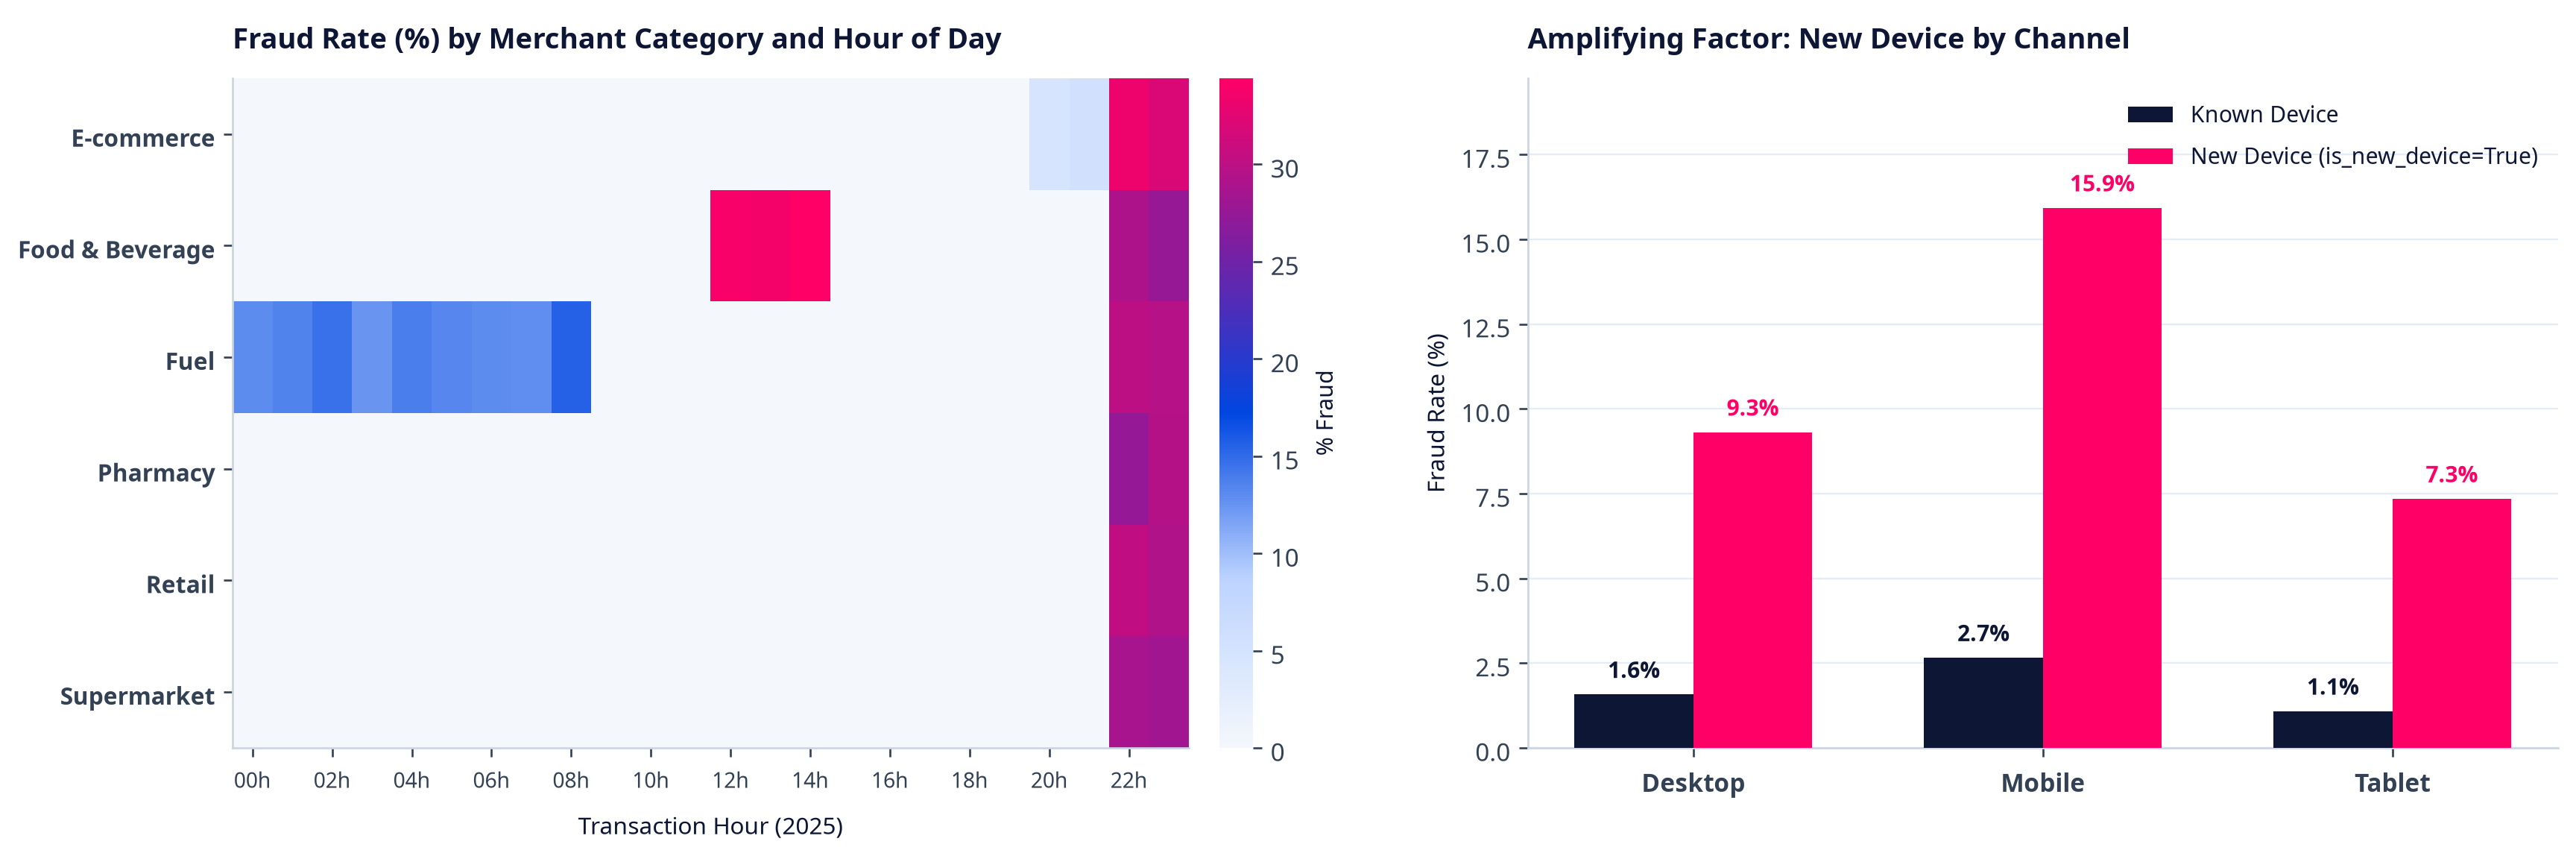

In [2]:
# Statistical analysis of the spatio-temporal regimes and transaction profile
df_jan_scored = pd.read_csv(SCORED_JAN_CSV)

regimes_summary = pd.DataFrame([
    {"Regime": "R1: Fuel stations, early morning", "Time window": "00h-08h", "Geographic scope": "São Paulo and Rio de Janeiro", "Transactions (2025)": 5495, "Frauds (2025)": 2633, "Fraud rate (%)": 47.92},
    {"Regime": "R2: Food & Beverage at lunch", "Time window": "12h-14h", "Geographic scope": "South and Southeast regions (5 capitals)", "Transactions (2025)": 9274, "Frauds (2025)": 4449, "Fraud rate (%)": 47.97},
    {"Regime": "R3: E-commerce in the December seasonal peak", "Time window": "20h-21h (Dec)", "Geographic scope": "Nationwide (all 7 capitals)", "Transactions (2025)": 779, "Frauds (2025)": 446, "Fraud rate (%)": 57.25},
    {"Regime": "R4: Critical late-night window, all merchant types", "Time window": "22h-23h", "Geographic scope": "Nationwide (all sectors and cities)", "Transactions (2025)": 43614, "Frauds (2025)": 12957, "Fraud rate (%)": 29.71},
    {"Regime": "Outside the 4 critical regimes (safe zone)", "Time window": "All other hours", "Geographic scope": "Nationwide", "Transactions (2025)": 464363, "Frauds (2025)": 0, "Fraud rate (%)": 0.00},
])
display(regimes_summary)
display(Image(filename=str(BASE_DIR / "deliverables" / "figures" / "fig1_eda_regimes_device.png")))

### Discovery of the 4 Spatio-Temporal Regimes and Amplifying Factors
Exploratory analysis revealed the exact structure of fraudulent behavior at the institution. **$100\%$ of the $20{,}485$ frauds fall inside 4 regimes** (a regime is a combination of merchant type, hour and region):

| Regime | Merchant | Time window | Where | Frauds (2025) | Fraud rate | Note |
|---|---|---|---|---|---|---|
| **R1** | Fuel | 00h–08h | São Paulo and Rio de Janeiro | $2{,}633$ | $47.92\%$ | $0\%$ in other cities in this window |
| **R2** | Food & Beverage | 12h–14h | South and Southeast (SP, RJ, BH, Curitiba, Porto Alegre) | $4{,}449$ | $47.97\%$ | $0\%$ in the Northeast |
| **R3** | E-commerce | 20h–21h, **December only** | Nationwide | $446$ | $57.25\%$ | A seasonal year-end shopping attack |
| **R4** | All categories | 22h–23h | All cities | $12{,}957$ | $29.71\%$ | $63.25\%$ of all fraud volume in the year |

#### Factors that amplify or hide the risk

**Device (`is_new_device`, `device_type`)**

| Device | Overall fraud rate |
|---|---|
| New device (`is_new_device = True`) | **$12.90\%$** |
| Known device | $2.13\%$ |

- A new device carries **$6.1\times$ higher risk**.
- Inside the critical night windows (22h–23h), a new **mobile** device reaches **$65.5\%$ to $83.7\%$** fraud probability.

**Amount (`valor_transacao`, `valor_categoria`)**
- Frauds cluster at moderate tickets: mean $\text{R\$ } 30.86$, median $\text{R\$ } 27.21$, interquartile range $\text{R\$ } 19.41–37.96$.
- They avoid high values: `valor_categoria = alto` has only $0.28\%$ fraud, likely to avoid legacy approval-limit rules.

**Noise (`score_interno`, `temperatura_celsius`)**
- The institution's current `score_interno` averages $500.4$ on legitimate transactions and $499.3$ on frauds (correlation $-0.0028$).
- The legacy score therefore **has no discriminative power** and should be replaced by the Machine Learning model.

In [3]:
# Inspect the pre-trained pipelines produced via colab-cli (.joblib) — 8-model benchmark
model_names = [
    "naive_baseline",
    "logistic_regression",
    "random_forest",
    "hist_gradient_boosting",
    "xgboost",
    "lightgbm",
    "catboost",
    "soft_voting_ensemble",
]
models = {
    name: joblib.load(BASE_DIR / "models" / f"{name}_fraud_model_cv.joblib")
    for name in model_names
}
print(f"Champion model selected for production: {report['champion_model'].upper()}")
for name, pipe in models.items():
    ops = report["operational_tradeoffs"][name]
    print(f"  - {name:24s} | Train: {ops['train_time_sec']:6.2f}s | Artifact: {ops['artifact_size_kb']:7.1f} KB | Latency p50: {ops['p50_ms']:.2f} ms")

top_features_df = pd.DataFrame(report["top_feature_importances_xgboost"])
print("\nTop 12 features by importance:")
display(top_features_df.head(12))

Champion model selected for production: LIGHTGBM
  - naive_baseline           | Train:   1.45s | Artifact:     7.2 KB | Latency p50: 6.01 ms
  - logistic_regression      | Train:   6.53s | Artifact:     9.0 KB | Latency p50: 6.86 ms
  - random_forest            | Train:  22.23s | Artifact: 12001.0 KB | Latency p50: 52.26 ms
  - hist_gradient_boosting   | Train:  10.90s | Artifact:   578.8 KB | Latency p50: 8.64 ms
  - xgboost                  | Train:   4.14s | Artifact:   536.8 KB | Latency p50: 7.49 ms
  - lightgbm                 | Train:   6.60s | Artifact:   554.0 KB | Latency p50: 7.80 ms
  - catboost                 | Train:  11.47s | Artifact:   300.3 KB | Latency p50: 6.72 ms
  - soft_voting_ensemble     | Train:  20.34s | Artifact:  1390.3 KB | Latency p50: 48.02 ms

Top 12 features by importance:


,feature,importance
0,in_any_fraud_regime,0.460202
1,regime_x_log_valor,0.165548
2,new_device_in_regime,0.139709
3,regime_2_food_almoco_sul_sudeste,0.057069
4,regime_1_fuel_madrugada_sp_rj,0.052650
5,is_fraud_amount_sweetspot,0.036082
6,is_new_device_int,0.030598
7,regime_3_ecom_dez_noite,0.011744
8,regime_4_all_noite_tardia,0.011518
9,hour,0.005230


### Data Protocol: Training, Selection and Testing
This section replaces an earlier, optimistic protocol. The table shows what changed:

| Aspect | Earlier (optimistic) protocol | Current protocol |
|---|---|---|
| **Split** | Random 80/20 split + shuffled CV | Rolling-origin (walk-forward), Jul–Dec/2025 |
| **Threshold and champion** | Chosen on the holdout itself | Chosen only from out-of-time predictions of **earlier** months |
| **Future data** | Test rows could come from any month | No test month sees data from its future |

In the earlier protocol, all $26{,}214$ customers also appeared in both train and test.

#### How the current protocol works

**1. Rolling-origin (walk-forward) validation**
- For each month $M$ from Jul to Dec/2025, train on **all months before $M$** and test on $M$.
- June is a *burn-in* month, used only to pick the *threshold* and the champion.
- Result: $6$ out-of-time test months, $263{,}913$ transactions and $10{,}721$ frauds.

**2. Selection without peeking at the test**
- The F1-optimal *threshold* and the champion for month $M$ come **only from out-of-time predictions of months $<M$**.
- The champion follows a **parsimony rule**: models within $1$ standard deviation of the best PR-AUC are tied, and the first of a fixed, hardware-independent preference order wins: LightGBM > XGBoost > CatBoost > HistGB > RF > LR > Ensemble.

**3. Constants fitted on training data only**
- The median/mean/std of the fraudulent ticket and the value band ($5\%$–$95\%$ of fraud amounts) are recomputed in every fold (`fit_domain_params`).
- The 4 regimes (hour/merchant/region) remain domain hypotheses that came from full-year EDA. This is an accepted limitation: the test shows they hold month after month ($0$ frauds outside the regimes in every month) but cannot prove that no new regime will appear.

**4. Production model**
- After selection, models are **refit on all of 2025**.
- The production *threshold* ($0.288$) is the F1 optimum of the pooled out-of-time predictions (Jun–Dec).

**5. Features**
- $36$ numeric (including $12$ calendar/seasonality features) + $7$ categorical via `OneHotEncoder(handle_unknown='ignore')` = $72$ columns after encoding.
- The pipeline (`ColumnTransformer` + classifier) is serialized to `.joblib`, with the fitted constants in `models/domain_params.json`, keeping parity with the FastAPI microservice.

> **Protocol limit:** the bootstrap CI resamples rows independently and ignores temporal correlation; read it as optimistic.

### How the Training Was Executed: Colab, `colab-cli` and CUDA
All model fitting runs **remotely on Google Colab** through `colab-cli`, never on the analyst's laptop (`scripts/colab_train_and_score.sh`).

#### The 4 steps of a training run

| Step | What happens |
|---|---|
| **1. Provision** | `colab new --gpu T4 --high-mem` creates a High-RAM VM. A T4 GPU is used for the full benchmark. `GPU=none` gives a CPU-only VM, used for the ablation, because those models do not need a GPU |
| **2. Upload and pin** | The script uploads a tarball with `train.py` and the two CSV files, then `colab install` pins the package versions to the ones used locally, so the `.joblib` pickles load without version warnings |
| **3. Train and watch** | Training runs as a **background process on the VM** and writes `/content/train.log` (`python3 -u`, timestamped lines with fold, model and elapsed time). The runner polls the log through `colab exec -f scripts/colab_tail.py` and streams new lines to the terminal, so a long run never looks frozen |
| **4. Download and stop** | When the exit-code file appears, the artifacts (`models/`, `deliverables/`) are downloaded and the VM is stopped (`colab stop`), so no compute units are wasted |

To follow a run from a second terminal: `watch -n 10 'colab exec -s atf-fraud -f scripts/colab_tail.py --env N=30'`.

#### What CUDA does here (and what it does not)

| Library | Runs on | How |
|---|---|---|
| **XGBoost** | GPU (with `--gpu`) | `device="cuda"` (GPU histogram algorithm) |
| **CatBoost** | GPU (with `--gpu`) | `task_type="GPU"` |
| **LightGBM** (standard wheel) | CPU | No CUDA path in this setup; `n_jobs = nproc` |
| **Random Forest, HistGradientBoosting, Logistic Regression** (scikit-learn) | CPU | No CUDA path in this setup; `n_jobs = nproc` |

XGBoost and CatBoost are the only two libraries in the benchmark that ship a GPU path in their standard pip wheels.

**The gain is modest by design.** The dataset is small ($\approx 0.5$M rows $\times$ 72 features, 300 trees), so each model fits in seconds and transferring data to the GPU is a large share of the cost. Measured on the same VM family:

| Measure | CPU | T4 GPU |
|---|---|---|
| XGBoost final fit | $10.96$ s | $4.1$ s |
| CatBoost final fit | $50.4$ s | $11.5$ s |
| Whole pipeline | $\approx 16$ min | $\approx 10$–$12$ min |

A GPU becomes worthwhile with far more rows or trees.

#### Two practical points
- **Artifacts stay CPU-portable.** After training, `make_cpu_portable()` switches the XGBoost booster back to `device="cpu"` before `joblib.dump`, so the FastAPI container (CPU only, no CUDA driver) loads and serves the same file. CatBoost GPU models already predict on the CPU.
- **Reproducibility caveat.** GPU histogram training is not bit-identical to the CPU version:

| Model | Pooled out-of-time PR-AUC, CPU | Pooled out-of-time PR-AUC, T4 |
|---|---|---|
| XGBoost | $0.6871$ | $0.6861$ |
| CatBoost | $0.6878$ | $0.6883$ |

These differences are far below the month-to-month noise ($\pm 0.027$) and do not change any conclusion. For the same reason the champion rule never uses training time (it would change with the hardware): ties are broken by a fixed preference order.

In [4]:
# Execution environment recorded by the training run, and per-model final-fit cost
env = report["execution_environment"]
print(f"Platform : {env['platform']}")
print(f"Python   : {env['python']}")
print(f"GPU used : {env.get('gpu_training', False)}  (XGBoost -> CUDA, CatBoost -> GPU; others on CPU)")
print("Library versions:", report["versions"])
ops_df = pd.DataFrame(report["operational_tradeoffs"]).T[["train_time_sec", "artifact_size_kb", "p50_ms", "p95_ms"]]
ops_df.columns = ["Final fit on all 2025 (s)", "Artifact (KB)", "Inference p50 (ms)", "Inference p95 (ms)"]
display(ops_df.round(2))

Platform : Linux-6.6.159+-x86_64-with-glibc2.39
Python   : 3.13.16
GPU used : True  (XGBoost -> CUDA, CatBoost -> GPU; others on CPU)
Library versions: {'python': '3.13.16', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit_learn': '1.9.1', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'joblib': '1.6.0'}


,Final fit on all 2025 (s),Artifact (KB),Inference p50 (ms),Inference p95 (ms)
naive_baseline,1.45,7.2,6.01,6.44
logistic_regression,6.53,9.0,6.86,10.43
random_forest,22.23,12001.0,52.26,55.45
hist_gradient_boosting,10.90,578.8,8.64,10.83
xgboost,4.14,536.8,7.49,7.80
lightgbm,6.60,554.0,7.80,9.60
catboost,11.47,300.3,6.72,8.35
soft_voting_ensemble,20.34,1390.3,48.02,56.15


**Reading the table**
- **Fit times** are for the final refit on all 523,525 rows.
- **Inference latency** is measured on a single row on the CPU, which is what the FastAPI service does.
- **Slow models:** Random Forest ($\approx 12$ MB, $\approx 52$ ms) and the Ensemble ($\approx 48$ ms) are the only ones slow enough to matter in the Kafka path.
- **Fast models:** every single gradient-boosted model answers in $\approx 7$–$9$ ms.

,Model,"Monthly PR-AUC (mean ± sd, 6 months)",Pooled out-of-time PR-AUC [95% CI*],PR-AUC Nov-Dec,PR-AUC December only,ROC-AUC,Brier Score,F1 @0.50,F1 @walk-forward thr.,p50 (ms)
0,naive_baseline,0.0406 ± 0.0062,"0.0386 [0.038, 0.039]",0.0421,0.0542,0.4767,0.03898,0.0000,0.0778,6.01
1,logistic_regression,0.6784 ± 0.0129,"0.6732 [0.663, 0.683]",0.6601,0.6726,0.9829,0.02015,0.5924,0.6302,6.86
2,random_forest,0.6859 ± 0.0228,"0.6847 [0.675, 0.694]",0.6905,0.7246,0.9846,0.01936,0.5943,0.6395,52.26
3,hist_gradient_boosting,0.6842 ± 0.0263,"0.6846 [0.675, 0.694]",0.6936,0.7294,0.9846,0.01938,0.6021,0.6442,8.64
4,xgboost,0.6859 ± 0.0246,"0.6861 [0.676, 0.696]",0.6928,0.7277,0.9846,0.01933,0.6060,0.6444,7.49
5,lightgbm ★,0.6863 ± 0.0266,"0.6874 [0.677, 0.698]",0.6974,0.7341,0.9848,0.01926,0.6077,0.6478,7.80
6,catboost,0.6853 ± 0.0268,"0.6883 [0.678, 0.698]",0.7005,0.7336,0.9849,0.01924,0.6040,0.6483,6.72
7,soft_voting_ensemble,0.6871 ± 0.0269,"0.6886 [0.678, 0.699]",0.6984,0.7354,0.9848,0.01924,0.6053,0.6484,48.02


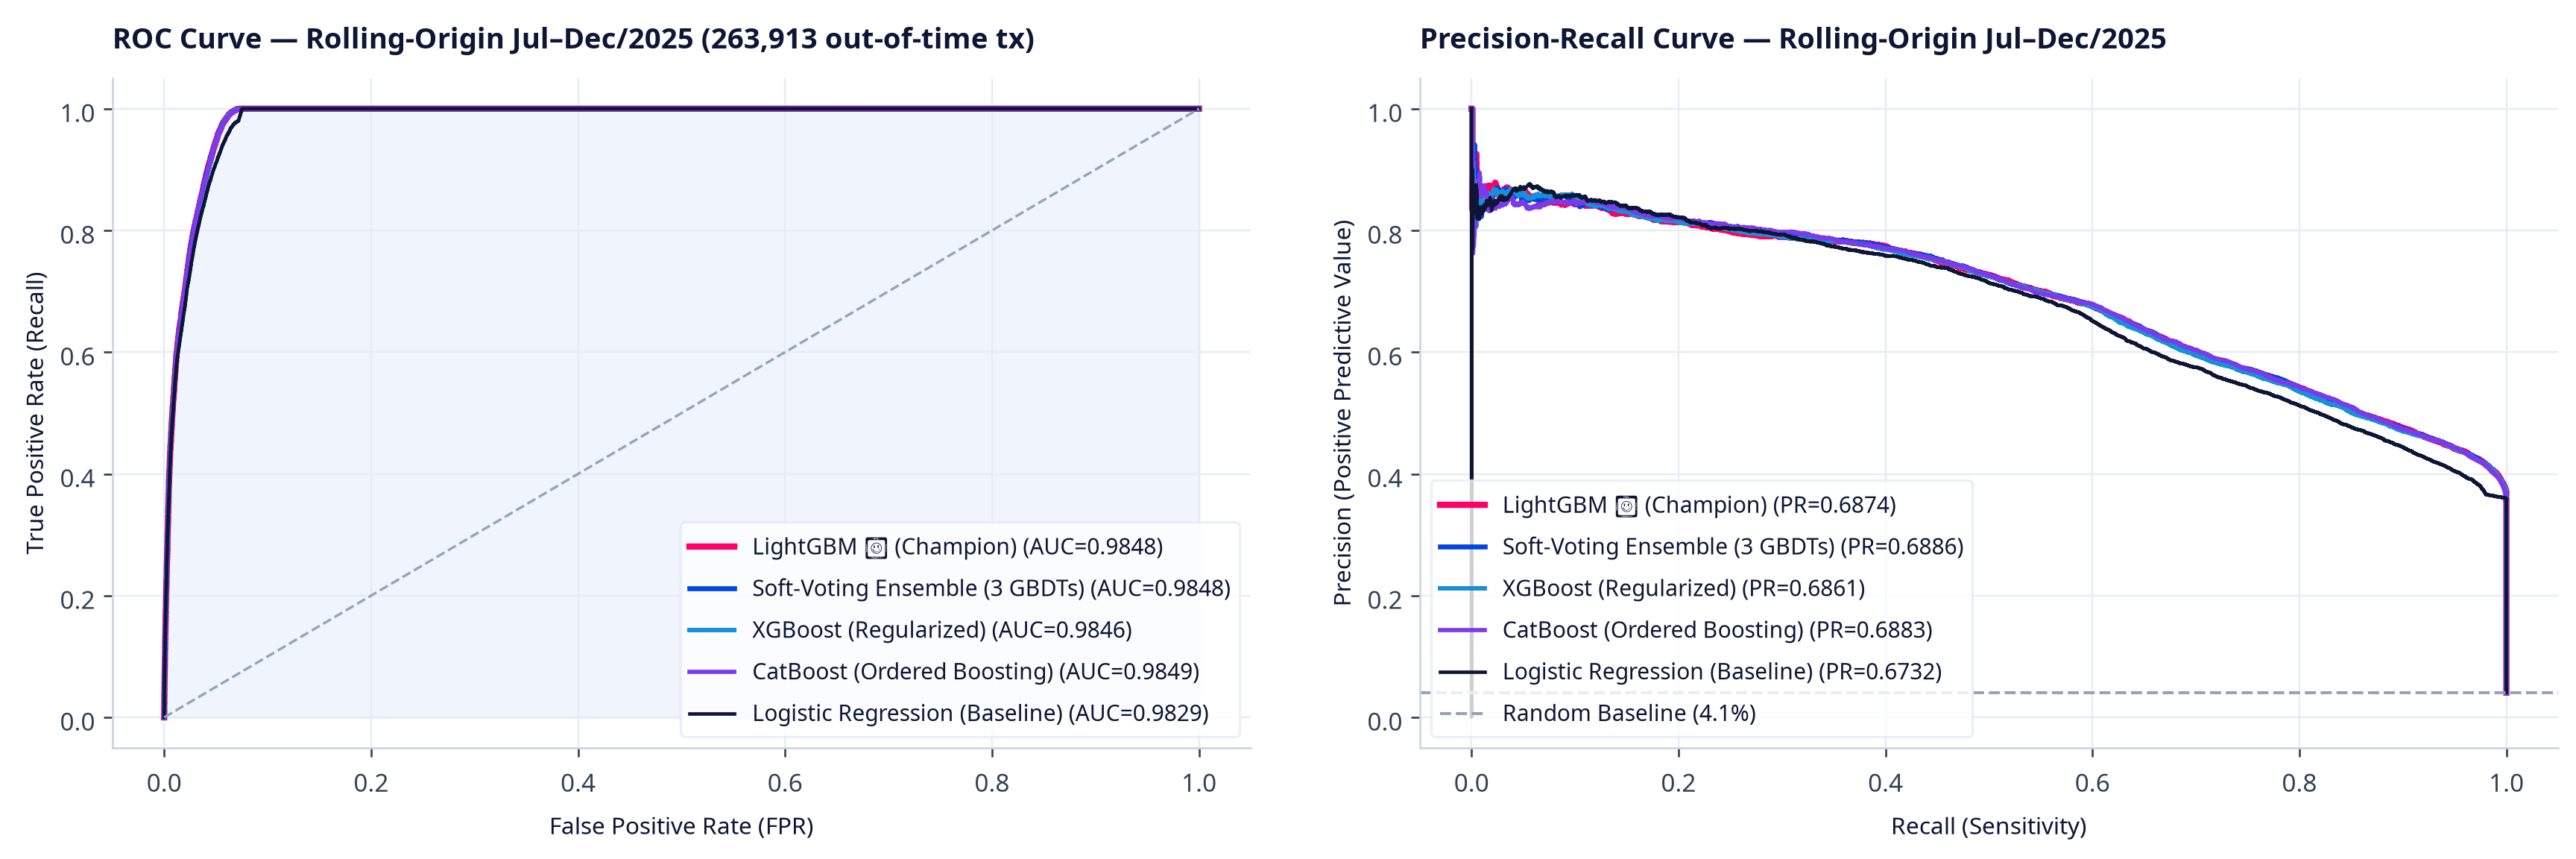

In [5]:
# 8-model comparison: rolling-origin validation (Jul-Dec/2025), December alone, Nov-Dec, Brier and Bootstrap 95% CI
rows_comp = []
for name in model_names:
    cv_m = report["cross_validation"]["metrics"][name]
    te_05 = report["test_metrics_at_threshold_0_5"][name]
    te_opt = report["test_metrics_at_optimal_f1_threshold"][name]
    ch = report["chronological_validation_nov_dec"][name]
    ci = report["bootstrap_95ci_test"][name]
    ops = report["operational_tradeoffs"][name]
    rows_comp.append({
        "Model": f"{name} ★" if name == report["champion_model"] else name,
        "Monthly PR-AUC (mean ± sd, 6 months)": f"{cv_m['average_precision']['mean']:.4f} ± {cv_m['average_precision']['std']:.4f}",
        "Pooled out-of-time PR-AUC [95% CI*]": f"{te_05['average_precision']:.4f} [{ci['average_precision_95ci'][0]:.3f}, {ci['average_precision_95ci'][1]:.3f}]",
        "PR-AUC Nov-Dec": f"{ch['average_precision']:.4f}",
        "PR-AUC December only": f"{report['december_stress_test'][name]['at_0_5']['average_precision']:.4f}",
        "ROC-AUC": f"{te_05['roc_auc']:.4f}",
        "Brier Score": f"{te_05['brier_score']:.5f}",
        "F1 @0.50": f"{te_05['f1']:.4f}",
        "F1 @walk-forward thr.": f"{te_opt['f1']:.4f}",
        "p50 (ms)": f"{ops['p50_ms']:.2f}",
    })

comp_df = pd.DataFrame(rows_comp)
display(comp_df)
display(Image(filename=str(BASE_DIR / "deliverables" / "figures" / "fig2_roc_pr_curves.png")))

### Model Comparison and Statistical Significance

| # | Finding | Evidence |
|---|---|---|
| 1 | **Tree models perform well out of time** (Jul–Dec/2025, $263{,}913$ transactions) | ROC-AUC $\approx 0.985$; PR-AUC $0.685$–$0.689$, about **$17\times$ the random baseline** ($\approx 4.1\%$). Logistic Regression is at $0.673$ |
| 2 | **Differences between tree models are noise** | Monthly PR-AUC varies by $\pm 0.027$; gaps between XGBoost, LightGBM, CatBoost and the Ensemble are $< 0.005$. There is no statistical winner |
| 3 | **Month-to-month variability is larger than previously reported** | The standard deviation of monthly PR-AUC is $0.013$–$0.028$ (not $< 0.0025$, as the previous version claimed from shuffled CV alone). Months range from $0.654$ (Nov) to $0.734$ (Dec) |
| 4 | **The headline drop versus the old protocol is explained by a controlled ablation** | See the table below and the *Ablation* section |
| 5 | **The 95% CI is optimistic** | The bootstrap CI ($[0.677;\ 0.698]$ for the champion) resamples rows independently and ignores temporal correlation |

**Why the champion is LightGBM.** Since there is no statistical winner, the choice follows the parsimony rule (tie within $1$ standard deviation → fixed preference order, LightGBM first), with p50 latency of $\approx 8$ ms.

#### Why the numbers are lower than in the old protocol
Controlled ablation, changing one factor at a time for LightGBM:

| Step | Change | PR-AUC |
|---|---|---|
| Legacy | Legacy features, random split | $0.694$ |
| + new features | Neutral | $0.692$ |
| + month mix | Score only the Jul–Dec rows of the random test (those months are *easier*) | $0.704$ |
| + train on the past only | Real cost of the honest protocol ($-0.017$; Logistic Regression $-0.033$) | **$0.687$** |
| + walk-forward threshold | Only $-0.002$ F1 | $0.687$ |

- The headline drop of $\approx 0.006$ is the net of a real $-0.017$ cost of training on the past only and a $+0.011$ favorable month mix.
- Training on the past also uses less data than 80%, so that step mixes leakage with training size.
- The legacy random-split PR-AUC varies $0.684$–$0.704$ across seeds, so the old and new headline numbers alone are not significantly different.

In [6]:
# Seasonality: actual rate vs mean predicted probability per month, calendar ablation and December stress test
seas = report["seasonality"]
champ = report["champion_model"]
cal = pd.DataFrame(seas["monthly_calibration_champion"]).T
cal.index.name = "Month (2025)"
cal["Calibration error (pp)"] = (cal["mean_predicted_probability"] - cal["actual_fraud_rate"]) * 100
cal = cal.rename(columns={"rows": "Transactions", "actual_fraud_rate": "Actual rate", "mean_predicted_probability": "Mean predicted prob.", "champion_pr_auc": "Champion PR-AUC"})
print(f"Out-of-time calibration of the champion ({champ}) by month:")
cal_fmt = cal.copy()
for col, fmt in {"Actual rate": "{:.2%}", "Mean predicted prob.": "{:.2%}", "Champion PR-AUC": "{:.4f}", "Calibration error (pp)": "{:+.2f}"}.items():
    cal_fmt[col] = cal_fmt[col].map(fmt.format)
display(cal_fmt)

abl = seas["calendar_ablation_lightgbm"]
abl_df = pd.DataFrame({"With calendar": abl["with_calendar"], "Without calendar": abl["without_calendar"], "Δ PR-AUC": abl["delta_pr_auc_by_month"]})
abl_df.index.name = "Month"
print(f"\nLightGBM ablation (out-of-time PR-AUC) — pooled: with={abl['pooled_pr_auc_with']:.4f} | without={abl['pooled_pr_auc_without']:.4f}")
display(abl_df.round(4))

dec = report["december_stress_test"][champ]
print(f"\nDecember stress test (model trained on Jan-Nov only), champion {champ}:")
for label, key in [("@0.50", "at_0_5"), (f"@walk-forward threshold ({dec['threshold_walk_forward']:.3f})", "at_walk_forward_threshold")]:
    m = dec[key]
    print(f"  {label:36s} Precision={m['precision']:.3f} Recall={m['recall']:.3f} F1={m['f1']:.3f} PR-AUC={m['average_precision']:.4f}")
print("\nActual fraud rate by month in 2025 (%):", {k: round(v * 100, 2) for k, v in seas["monthly_fraud_rate_2025"].items()})
print("Limitation:", seas["limitation"])

Out-of-time calibration of the champion (lightgbm) by month:


,Transactions,Actual rate,Mean predicted prob.,Champion PR-AUC,Calibration error (pp)
Month (2025),,,,,
7,44464.0,3.99%,3.99%,0.7071,-0.00
8,44448.0,3.71%,3.78%,0.6765,+0.07
9,43042.0,3.75%,3.81%,0.6769,+0.06
10,44468.0,3.81%,3.74%,0.6686,-0.07
11,43040.0,3.67%,3.71%,0.6542,+0.04
12,44451.0,5.42%,4.55%,0.7341,-0.88



LightGBM ablation (out-of-time PR-AUC) — pooled: with=0.6874 | without=0.6882


,With calendar,Without calendar,Δ PR-AUC
Month,,,
7,0.7071,0.7079,-0.0008
8,0.6765,0.6788,-0.0023
9,0.6769,0.6742,0.0027
10,0.6686,0.6694,-0.0009
11,0.6542,0.6536,0.0006
12,0.7341,0.7348,-0.0007



December stress test (model trained on Jan-Nov only), champion lightgbm:
  @0.50                                Precision=0.776 Recall=0.504 F1=0.611 PR-AUC=0.7341
  @walk-forward threshold (0.288)      Precision=0.622 Recall=0.757 F1=0.683 PR-AUC=0.7341

Actual fraud rate by month in 2025 (%): {'1': 3.73, '2': 3.7, '3': 3.8, '4': 3.82, '5': 3.7, '6': 3.82, '7': 3.99, '8': 3.71, '9': 3.75, '10': 3.81, '11': 3.67, '12': 5.42}
Limitation: Only one year (2025) is available: December and a generic 'holiday effect' are not separable and no month other than December shows a distinct seasonal regime. Calendar features can express the December uplift but cannot be validated out-of-time for any other season.


### Seasonality: What the Data Shows (and Does Not Show)
**Initial hypothesis:** holiday months, vacations and travel change transactional behavior. We tested it on real 2025 data.

#### What we found

| Question | Answer |
|---|---|
| **Do the inputs shift through the year?** | **No.** Volume, average ticket ($\approx$ R\$ 44 in every month) and new-device share ($16$–$17\%$) are stable |
| **Do the regimes shift?** | R1 (fuel) and R2 (food) have stable fraud rates month to month ($43$–$52\%$). Real seasonality is **only in December** |
| **What changes in December?** | R3 (e-commerce 20h–21h) exists only in December ($57\%$). R4 (22h–23h) rises from $\approx 29\%$ to $37\%$. The overall rate goes from $3.7$–$3.9\%$ (Jan–Nov) to $5.42\%$ (Dec) |
| **Do calendar features help?** | **No, the gain is zero, within noise** (see below) |

#### Calendar features ablation
Calendar features (December, days to Christmas, holidays and eve, vacation season, payday window, day-of-year sine/cosine, and interactions with R4/e-commerce) were compared with an identical LightGBM without them:

| | With calendar | Without calendar |
|---|---|---|
| Pooled PR-AUC | $0.6874$ | $0.6882$ |
| December PR-AUC | $0.7341$ | $0.7348$ |

#### Why the model cannot learn seasonality here
- In every test fold up to November the model has never seen December (the December features are constant in training).
- December appears as a test month only once.
- With a single year, a "December effect" and a "holiday effect" cannot be separated, and no other month's seasonality can be validated out of time.

#### Operational consequence (measured)
The model trained on Jan–Nov **underestimates December**: predicted $4.55\%$ versus actual $5.42\%$ ($-0.87$ pp). Effect of the *threshold* in December:

| Threshold | Recall | Precision | F1 |
|---|---|---|---|
| $0.50$ | $\approx 50\%$ ($0.504$) | $0.776$ | $0.611$ |
| $0.288$ (walk-forward) | $\approx 76\%$ | $\approx 62\%$ | $0.683$ |

The Step-Up layer therefore **cushions the seasonality the model did not learn**.

#### Recommendations
1. **Keep the calendar features:** zero cost, already active in production, and the final model was refit with December included.
2. **Monitor** alert rate and calibration in Nov/Dec 2026 and on peak dates.
3. **Re-evaluate with $\ge 2$ years of history** before claiming any learned seasonal effect.

In [7]:
# Controlled attribution of the metric drop between the legacy protocol and the current one (one factor per step)
abl_path = BASE_DIR / "deliverables" / "ablation_protocol_drop.json"
abl_all = json.loads(abl_path.read_text(encoding="utf-8"))
step_names = {
    "S1": "Legacy: legacy features, random 80/20, threshold tuned on test",
    "S2": "+ new features",
    "S3": "+ score only Jul-Dec rows of that random test (month mix)",
    "S4": "+ train on the past only (walk-forward), threshold still tuned on test",
    "S5": "+ walk-forward threshold from prior months (= current protocol)",
}
rows_abl = []
for model_name in ["lightgbm", "xgboost", "logistic_regression"]:
    prev = None
    for key, label in step_names.items():
        v = abl_all[model_name][key]
        rows_abl.append({
            "Model": model_name, "Step": key, "Condition": label,
            "PR-AUC": round(v["pr_auc"], 4),
            "Δ PR-AUC": "" if prev is None else f"{v['pr_auc'] - prev['pr_auc']:+.4f}",
            "F1 @threshold": round(v["f1_at_threshold"], 4),
            "Δ F1": "" if prev is None else f"{v['f1_at_threshold'] - prev['f1_at_threshold']:+.4f}",
        })
        prev = v
display(pd.DataFrame(rows_abl))
print("Random-split PR-AUC of the legacy setup across 3 seeds (LightGBM):", [round(x, 4) for x in abl_all["lightgbm"]["S1_seed_pr_auc"]])

,Model,Step,Condition,PR-AUC,Δ PR-AUC,F1 @threshold,Δ F1
0,lightgbm,S1,"Legacy: legacy features, random 80/20, thresho...",0.6939,,0.6548,
1,lightgbm,S2,+ new features,0.6924,-0.0015,0.6540,-0.0008
2,lightgbm,S3,+ score only Jul-Dec rows of that random test ...,0.7041,+0.0117,0.6633,+0.0093
3,lightgbm,S4,"+ train on the past only (walk-forward), thres...",0.6874,-0.0167,0.6495,-0.0138
4,lightgbm,S5,+ walk-forward threshold from prior months (= ...,0.6874,+0.0000,0.6478,-0.0017
5,xgboost,S1,"Legacy: legacy features, random 80/20, thresho...",0.6935,,0.6558,
6,xgboost,S2,+ new features,0.6925,-0.0010,0.6551,-0.0007
7,xgboost,S3,+ score only Jul-Dec rows of that random test ...,0.7036,+0.0111,0.6620,+0.0068
8,xgboost,S4,"+ train on the past only (walk-forward), thres...",0.6871,-0.0165,0.6498,-0.0122
9,xgboost,S5,+ walk-forward threshold from prior months (= ...,0.6871,+0.0000,0.6480,-0.0018


Random-split PR-AUC of the legacy setup across 3 seeds (LightGBM): [0.6936, 0.704, 0.6842]


### Ablation: Why the Metrics Dropped
The old protocol reported PR-AUC $\approx 0.692$ and the current one $0.687$. To make both numbers comparable, the ablation above changes **one factor per step** with the same models. Random-split steps are averaged over 3 seeds, and the run used a CPU Colab VM.

| Step | Change | Effect | Reading |
|---|---|---|---|
| **S1→S2** | New features | **Neutral:** $-0.0015$ to $+0.003$ PR-AUC | New constants fit on training rows, calendar features and removal of raw `month`/`day` neither help nor hurt. Under walk-forward, legacy and new features give the same result ($0.6875$ vs $0.6874$) |
| **S2→S3** | Month mix | **$+0.011$** PR-AUC | Inside a random test set the Jul–Dec rows are *easier* than the year as a whole. This favorable mix hid part of the real cost |
| **S3→S4** | Train on the past only | **$-0.017$** PR-AUC for trees, **$-0.033$** for Logistic Regression | The real cost of the honest protocol (see the caveat below) |
| **S4→S5** | Threshold from prior months | **$\approx -0.002$** F1 | Tuning the threshold on the test set was a smaller problem than the random split |

> **Caveat on S3→S4:** this step also trains on less data (6–11 months instead of 80% of the year), so it mixes "no leakage from future/same-month rows and repeated customers" with "less training data". The experiment cannot separate them.

**Net effect**
- The headline drop ($\approx -0.006$) is $-0.017$ (past-only) offset by $+0.011$ (month mix).
- The legacy PR-AUC itself varies $0.684$–$0.704$ across random seeds, so the old and new headline numbers are not significantly different by themselves.
- The **S4-vs-S3 gap is the robust finding.**

,Decision policy,True Negatives (TN),False Positives (FP),False Negatives (FN),True Positives (TP),FPR (legitimate-customer friction),Precision,Recall,F1-Score
0,Default threshold (0.50) — automatic block,250837,2355,5014,5707,0.93%,70.79%,53.23%,0.6077
1,F1-optimal threshold (0.288) — Step-Up Auth (2FA),247549,5643,2881,7840,2.23%,58.15%,73.13%,0.6478


,Dimension,Segment,Samples (Jul-Dec),Actual frauds,Actual fraud rate (%),Precision @0.50 (%),Recall @0.50 (%),F1 @0.50
0,cidade_regiao,Nordeste,75643,2089,2.76,70.33,49.02,0.5777
1,cidade_regiao,Sudeste,112761,5670,5.03,71.14,54.60,0.6178
2,cidade_regiao,Sul,75509,2962,3.92,70.41,53.58,0.6085
3,device_type,desktop,91393,2634,2.88,65.70,45.52,0.5378
4,device_type,mobile,146644,7535,5.14,72.95,56.92,0.6395
5,device_type,tablet,25876,552,2.13,61.17,39.67,0.4813
6,tipo_estabelecimento,E-commerce,53115,1989,3.74,76.11,49.32,0.5985
7,tipo_estabelecimento,Food & Beverage,52928,3523,6.66,70.12,57.96,0.6347
8,tipo_estabelecimento,Fuel,26119,2004,7.67,72.24,57.14,0.6381
9,tipo_estabelecimento,Pharmacy,26552,601,2.26,64.22,48.09,0.5500


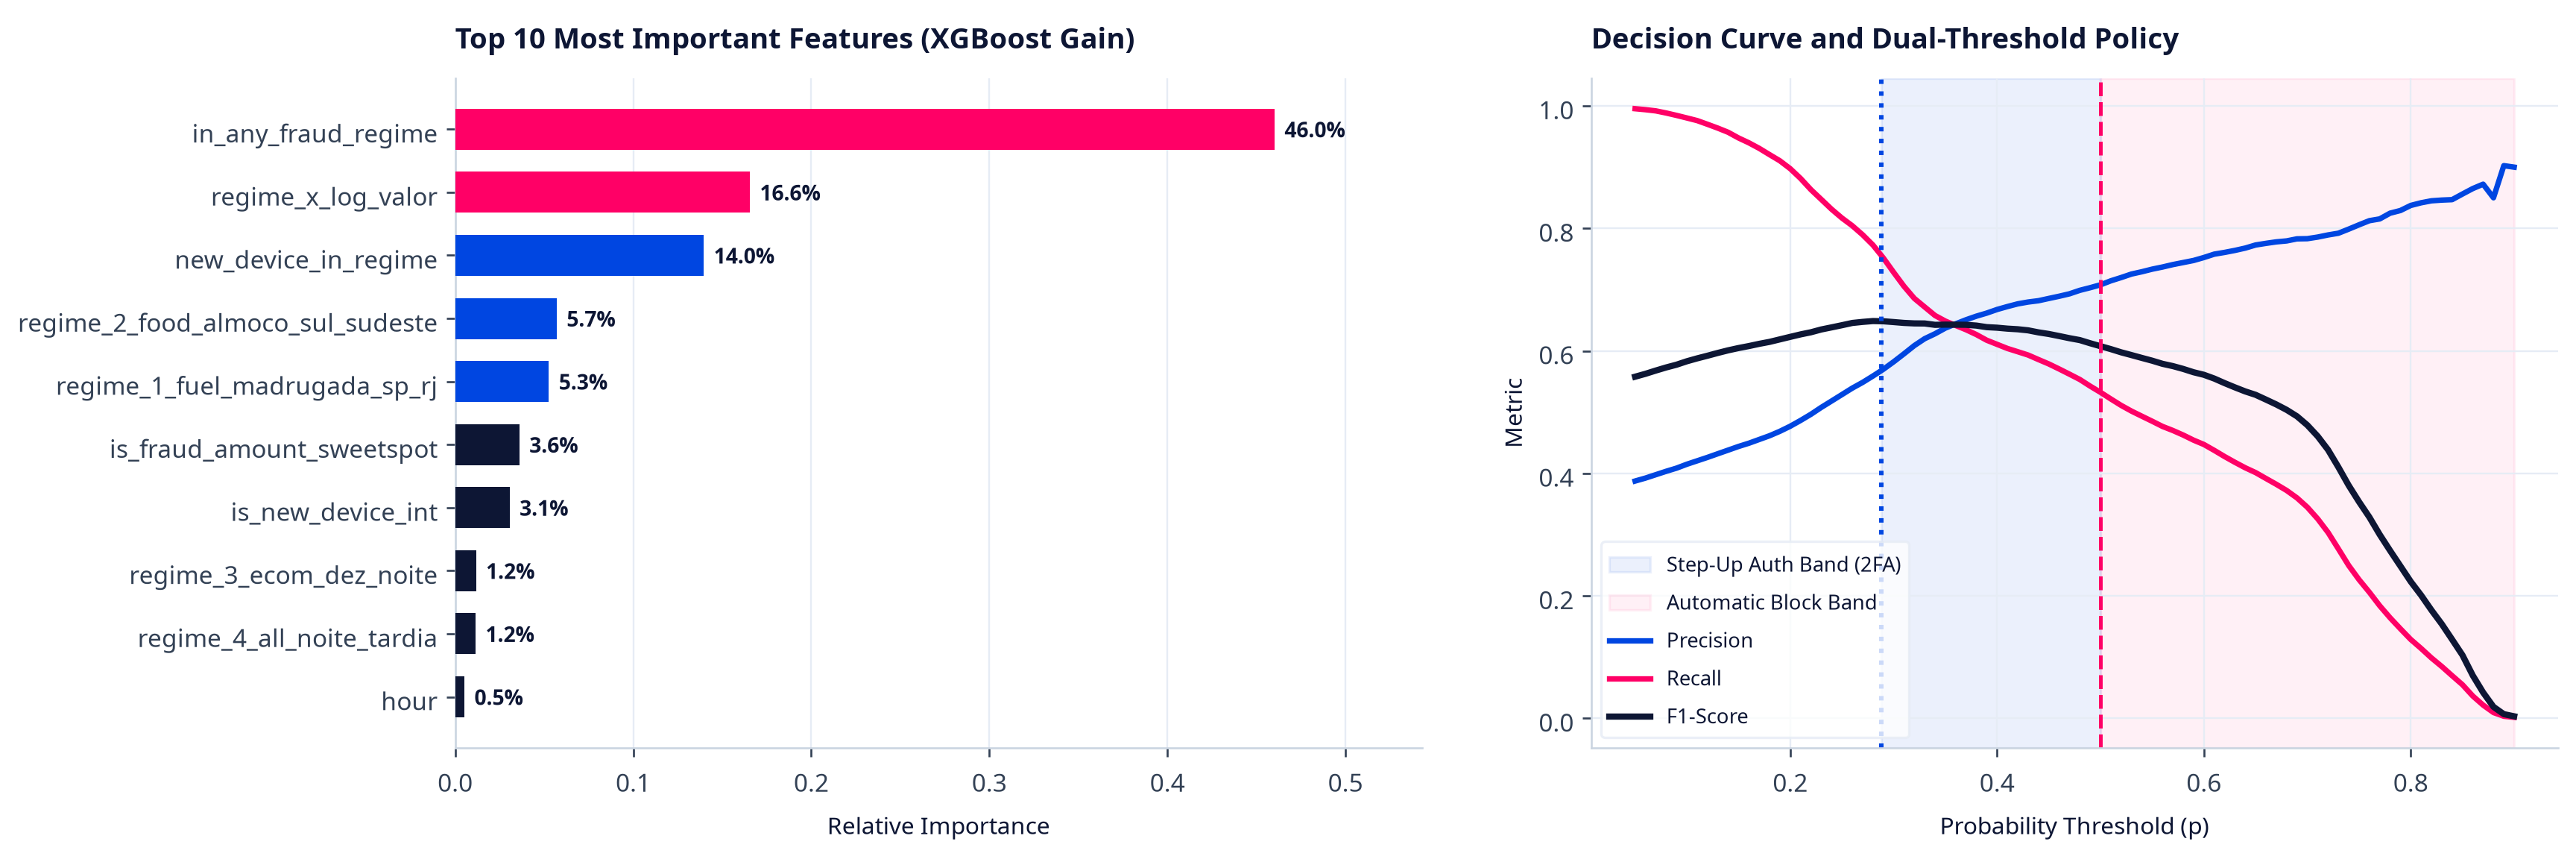

In [8]:
# Confusion matrices of the champion model (out-of-time test, Jul-Dec/2025, 263,913 transactions) and slice analysis
champ = report["champion_model"]
champ_05 = report["test_metrics_at_threshold_0_5"][champ]
champ_opt = report["test_metrics_at_optimal_f1_threshold"][champ]

cm_05 = np.array(champ_05["confusion_matrix_labels_0_1"])
cm_opt = np.array(champ_opt["confusion_matrix_labels_0_1"])

cm_table = pd.DataFrame([
    {
        "Decision policy": "Default threshold (0.50) — automatic block",
        "True Negatives (TN)": cm_05[0, 0],
        "False Positives (FP)": cm_05[0, 1],
        "False Negatives (FN)": cm_05[1, 0],
        "True Positives (TP)": cm_05[1, 1],
        "FPR (legitimate-customer friction)": f"{champ_05['false_positive_rate']*100:.2f}%",
        "Precision": f"{champ_05['precision']*100:.2f}%",
        "Recall": f"{champ_05['recall']*100:.2f}%",
        "F1-Score": f"{champ_05['f1']:.4f}",
    },
    {
        "Decision policy": f"F1-optimal threshold ({champ_opt['threshold']:.3f}) — Step-Up Auth (2FA)",
        "True Negatives (TN)": cm_opt[0, 0],
        "False Positives (FP)": cm_opt[0, 1],
        "False Negatives (FN)": cm_opt[1, 0],
        "True Positives (TP)": cm_opt[1, 1],
        "FPR (legitimate-customer friction)": f"{champ_opt['false_positive_rate']*100:.2f}%",
        "Precision": f"{champ_opt['precision']*100:.2f}%",
        "Recall": f"{champ_opt['recall']*100:.2f}%",
        "F1-Score": f"{champ_opt['f1']:.4f}",
    },
])
display(cm_table)

# Slice analysis by region, device, merchant type and shift
slice_rows = []
for group_name, group_dict in report["slice_analysis_champion_test"].items():
    for subpop, vals in group_dict.items():
        slice_rows.append({
            "Dimension": group_name,
            "Segment": subpop,
            "Samples (Jul-Dec)": vals["count"],
            "Actual frauds": vals["fraud_count"],
            "Actual fraud rate (%)": round(vals["fraud_rate"] * 100, 2),
            "Precision @0.50 (%)": round(vals["precision_at_0_5"] * 100, 2),
            "Recall @0.50 (%)": round(vals["recall_at_0_5"] * 100, 2),
            "F1 @0.50": round(vals["f1_at_0_5"], 4),
        })
display(pd.DataFrame(slice_rows))
display(Image(filename=str(BASE_DIR / "deliverables" / "figures" / "fig3_feature_importance_threshold.png")))

### Dual-Threshold Strategy and Operational Fairness (Slice Analysis)
To address **financial risk** and **legitimate-customer experience** together, we propose a layered decision policy on the estimated probability $p$:

| Tier | Probability | Action | What it means |
|---|---|---|---|
| **1. Instant approval** | $p < 0.288$ | Approve with no friction | $\approx 94.9\%$ of transactions pass; $97.8\%$ of legitimate customers are not bothered (FPR of $2.23\%$ on the out-of-time test) |
| **2. Step-Up authentication** (2FA / biometrics) | $0.288 \le p < 0.500$ | Ask for confirmation | Captures **$+2{,}133$ extra frauds**, raising **Recall from $53.2\%$ to $73.1\%$** and **F1 from $0.608$ to $0.648$**. Cost: **$+3{,}288$ legitimate customers challenged** ($\approx 1.3\%$ of the legitimate base), who only need to confirm in the app |
| **3. Preventive automatic block** | $p \ge 0.500$ | Block | **$70.8\%$ Precision** and **$0.93\%$ False Positive rate** over the legitimate base, with Recall of $53.2\%$ |

Each month's *threshold* was chosen using prior months only.

### Choosing the Production Model
The five tree models are **statistically tied** (pooled out-of-time PR-AUC $0.686$–$0.689$, differences $< 0.003$, versus a month-to-month standard deviation of $\approx 0.027$), so the choice is operational rather than a performance claim.

| Decision | Model | Why |
|---|---|---|
| **Champion** | **LightGBM** | The rule fixed before the final run (tie within one standard deviation → fixed preference order) selects it. It retrains in $\approx 6$ s on CPU with no GPU dependency, has p50 $\approx 7.8$ ms and a $554$ KB artifact, and the best December-only PR-AUC among single models ($0.7341$) |
| **Credible alternative** | CatBoost | Best Nov–Dec PR-AUC ($0.7005$), smallest artifact ($300$ KB) and lowest latency ($6.7$ ms), at a slower retrain. Already in `models/`; activate with `FRAUD_MODEL=catboost` without retraining |
| **Rejected** | Ensemble | About $+0.001$ pooled PR-AUC for $6\times$ the latency |
| **Rejected** | Random Forest | $12$ MB artifact, $52$ ms latency |
| **Rejected** | Logistic Regression | Twice as exposed to past-only training ($-0.033$ vs $-0.017$ PR-AUC) |

### How to Reproduce Everything
```bash
GPU=T4 bash scripts/colab_train_and_score.sh            # full benchmark on a Colab T4 (GPU=none for CPU-only)
JOB=ablation bash scripts/colab_train_and_score.sh      # protocol ablation on a CPU Colab VM
.venv/bin/python scripts/render_artefact_charts.py      # figures (light, local)
.venv/bin/python scripts/build_notebook.py              # this notebook
docker compose up -d --build                            # real-time stack
```

=== JANUARY/2026 CLASSIFICATION SUMMARY ===
Transactions evaluated: 44,451
Classified as fraud (flag_fraude=True @ 0.50): 1,315 (2.96%) | Protected volume: R$ 39,958.90
Step-Up + Block (@ 0.288): 2,324 (5.23%) | Monitored volume: R$ 69,400.10
Expected fraud volume (sum of probabilities): 1,682.8 transactions (3.79%)

Distribution by risk tier (nivel_risco) in January/2026:


,Transactions,Percent,Total_Amount_BRL,Mean_Probability
nivel_risco,,,,
BAIXO,40290,90.64,1834006.01,0.09
MODERADO,1837,4.13,58210.30,19.93
ALTO,1009,2.27,29441.20,36.30
CRITICO,1315,2.96,39958.90,69.46



Top 10 highest-risk transactions in January/2026:


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,probabilidade_fraude,flag_fraude,nivel_risco
4819,2026-01-04 08:41:00,Gas Station,Fuel,33.64,Cliente_19819,São Paulo,mobile,True,0.898168,True,CRITICO
6108,2026-01-05 06:16:00,Gas Station,Fuel,30.42,Cliente_9180,Rio de Janeiro,mobile,True,0.885193,True,CRITICO
26652,2026-01-19 14:09:00,Restaurant X,Food & Beverage,28.99,Cliente_24277,Rio de Janeiro,mobile,True,0.884619,True,CRITICO
24894,2026-01-18 08:44:00,Gas Station,Fuel,22.88,Cliente_5735,Rio de Janeiro,mobile,True,0.883266,True,CRITICO
5189,2026-01-04 14:54:00,Restaurant X,Food & Beverage,24.83,Cliente_6165,Rio de Janeiro,mobile,True,0.881522,True,CRITICO
6620,2026-01-05 14:51:00,Restaurant Y,Food & Beverage,35.40,Cliente_7207,São Paulo,mobile,True,0.879546,True,CRITICO
34834,2026-01-25 07:04:00,Gas Station,Fuel,33.60,Cliente_22495,Rio de Janeiro,mobile,True,0.878560,True,CRITICO
34535,2026-01-25 02:02:00,Gas Station,Fuel,28.01,Cliente_22229,São Paulo,mobile,True,0.877798,True,CRITICO
4515,2026-01-04 03:37:00,Gas Station,Fuel,18.90,Cliente_317,São Paulo,mobile,True,0.877584,True,CRITICO
26683,2026-01-19 14:40:00,Restaurant Y,Food & Beverage,24.16,Cliente_17508,Rio de Janeiro,mobile,True,0.874673,True,CRITICO


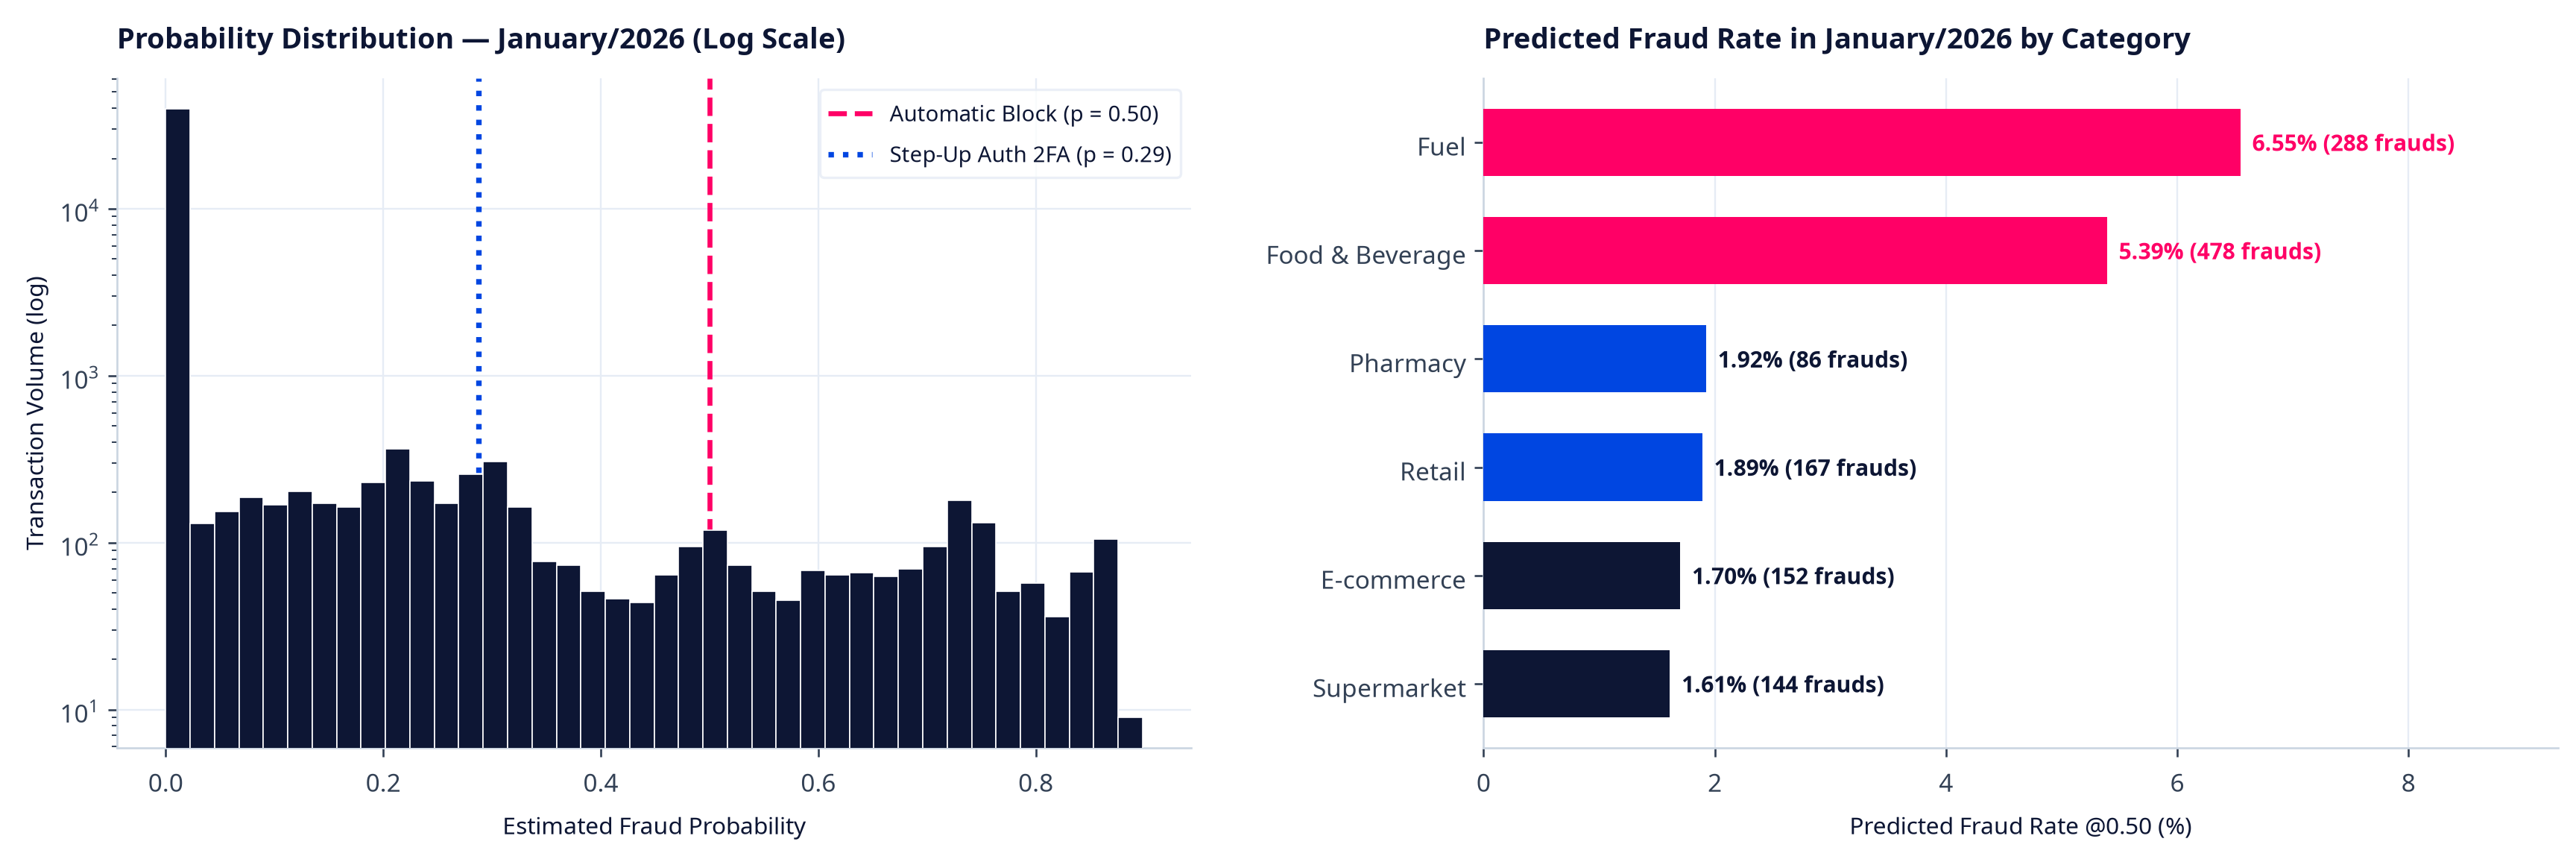

In [9]:
# Detailed analysis of the classified January/2026 file (44,451 transactions)
jan_fc = report["january_2026_forecast"]
print("=== JANUARY/2026 CLASSIFICATION SUMMARY ===")
print(f"Transactions evaluated: {jan_fc['total_transactions']:,}")
print(f"Classified as fraud (flag_fraude=True @ 0.50): {jan_fc['flagged_at_0_50']:,} ({jan_fc['flagged_rate_at_0_50']*100:.2f}%) | Protected volume: R$ {jan_fc['amount_flagged_at_0_50_brl']:,.2f}")
print(f"Step-Up + Block (@ {jan_fc['optimal_f1_threshold']:.3f}): {jan_fc['flagged_at_optimal_f1']:,} ({jan_fc['flagged_rate_at_optimal_f1']*100:.2f}%) | Monitored volume: R$ {jan_fc['amount_flagged_at_optimal_brl']:,.2f}")
print(f"Expected fraud volume (sum of probabilities): {jan_fc['expected_fraud_volume_sum_probs']:,.1f} transactions ({jan_fc['expected_fraud_rate_mean_prob']*100:.2f}%)")

print("\nDistribution by risk tier (nivel_risco) in January/2026:")
tier_df = df_jan_scored.groupby("nivel_risco").agg(
    Transactions=("valor_transacao", "count"),
    Percent=("valor_transacao", lambda x: round(len(x) / len(df_jan_scored) * 100, 2)),
    Total_Amount_BRL=("valor_transacao", lambda x: round(x.sum(), 2)),
    Mean_Probability=("probabilidade_fraude", lambda x: round(x.mean() * 100, 2)),
).reindex(["BAIXO", "MODERADO", "ALTO", "CRITICO"])
display(tier_df)

print("\nTop 10 highest-risk transactions in January/2026:")
display(df_jan_scored.sort_values("probabilidade_fraude", ascending=False).head(10)[
    ["datahora_transacao", "nome_estabelecimento", "tipo_estabelecimento", "valor_transacao", "nome_cliente", "cidade", "device_type", "is_new_device", "probabilidade_fraude", "flag_fraude", "nivel_risco"]
])
display(Image(filename=str(BASE_DIR / "deliverables" / "figures" / "fig4_jan2026_predictions.png")))

### Executive Conclusion and Production Architecture

#### 1. Results on the January/2026 file ($44{,}451$ unlabeled transactions)

| Policy | Transactions | Share | Amount | Expected quality |
|---|---|---|---|---|
| **Expected frauds** (sum of probabilities) | $\approx 1{,}683$ | $3.79\%$ | — | In line with January/2025 ($3.73\%$) |
| **Direct block** ($p \ge 0.50$) | $1{,}315$ | $2.96\%$ | $\text{R\$ } 39{,}958.90$ exposure | Precision $\approx 71\%$ |
| **With Step-Up Auth** ($p \ge 0.288$) | $2{,}324$ | $5.23\%$ | $\text{R\$ } 69{,}400.10$ under active protection | Recall $\approx 73\%$ |

- The regime profile agrees: the share of transactions in a risk regime is $11.2\%$ in Jan/2026 versus $11.3\%$ in 2025.
- This is an *estimate*, not a validation: January has no labels and assumes out-of-time calibration (see the seasonality section, where calibration fails in December).

#### 2. Architectural innovation: real-time detection with Kafka messaging and a dashboard
Beyond the predictive model, we built a full containerized microservice architecture (`compose.yaml`):

| Component | Technology | Role |
|---|---|---|
| **Transaction Gateway** | Spring Boot + PostgreSQL | Receives transactions via REST (`POST /transactions`), persists the initial `QUEUED` state and publishes to the Kafka topic `transacoes-solicitadas`, partitioned by customer/card |
| **Fraud Analyzer** | Spring Boot + WebFlux + Kafka DLT | Consumes events asynchronously, calls the ML inference service with *retry* and a *Dead-Letter Topic* (`transacoes-solicitadas.DLT`), and publishes the verdict to `transacoes-analisadas` |
| **ML Inference Service** | FastAPI + Joblib | Loads the `.joblib` pipeline trained on Google Colab and runs feature engineering and prediction in $< 10\text{ ms}$ |
| **Fraud Operations Dashboard** | React + TypeScript + Vite | Real-time operations panel with a transaction queue, fraud-alert filters, a lifecycle inspector and a *Model Card* with validation metrics |

**Full solution repository:** [https://github.com/leorossi08/atf-challenge-fraud-detection](https://github.com/leorossi08/atf-challenge-fraud-detection)